# Milestone 4: 13-identity classifier

This notebook extends the Milestone 1 ResNet50V2 classifier to all 13 shared identities. It uses the fixed M2 source split, with original portraits and ground-truth crops from the synthetic detection frames. Model selection uses validation loss; the test split remains unused here.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'src').is_dir():
    raise RuntimeError('Start Jupyter in the project root or notebooks directory')
sys.path.insert(0, str(ROOT))
from src.m4_classifier import train

RUN_DIR = ROOT / 'runs' / 'm4' / 'classifier13'
SOURCE_DIR = ROOT / 'data' / 'shared_pool'
print('Source:', SOURCE_DIR)
print('Output:', RUN_DIR)

Source: /home/zhang.jiaso/ondemand/data/sys/dashboard/batch_connect/sys/jupyterlab-ml-courses/ie7615-project1/data/shared_pool
Output: /home/zhang.jiaso/ondemand/data/sys/dashboard/batch_connect/sys/jupyterlab-ml-courses/ie7615-project1/runs/m4/classifier13


## Training

The classifier uses original train portraits and labeled portrait-region crops from M2 train frames. The same two input types from the validation split select the checkpoint. Each input type receives equal total loss weight. Training first fits a frozen ResNet50V2 head, then fine-tunes the backbone from the selected warm-up weights.

In [2]:
train(SOURCE_DIR, RUN_DIR, batch_size=8, warmup_epochs=15, finetune_epochs=30, seed=42)

2026-10-13 04:15:47.690905: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1791879348.075522 2570166 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1791879348.172822 2570166 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1791879349.507802 2570166 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1791879349.507838 2570166 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1791879349.507840 2570166 computation_placer.cc:177] computation placer alr

Epoch 1/15


I0000 00:00:1791879381.564793 2570240 cuda_dnn.cc:529] Loaded cuDNN version 90300


117/117 ━━━━━━━━━━━━━━━━━━━━ 22s 69ms/step - accuracy: 0.1955 - loss: 2.7905 - val_accuracy: 0.5511 - val_loss: 1.4238
Epoch 2/15
117/117 ━━━━━━━━━━━━━━━━━━━━ 5s 47ms/step - accuracy: 0.5642 - loss: 1.2898 - val_accuracy: 0.6311 - val_loss: 1.0565
Epoch 3/15
117/117 ━━━━━━━━━━━━━━━━━━━━ 6s 47ms/step - accuracy: 0.6786 - loss: 0.9968 - val_accuracy: 0.6711 - val_loss: 0.9400
Epoch 4/15
117/117 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - accuracy: 0.7978 - loss: 0.6656 - val_accuracy: 0.6756 - val_loss: 0.8792
Epoch 5/15
117/117 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - accuracy: 0.7992 - loss: 0.6181 - val_accuracy: 0.7022 - val_loss: 0.8128
Epoch 6/15
117/117 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step - accuracy: 0.8341 - loss: 0.5563 - val_accuracy: 0.7200 - val_loss: 0.7867
Epoch 7/15
117/117 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - accuracy: 0.8664 - loss: 0.4293 - val_accuracy: 0.6844 - val_loss: 0.8018
Epoch 8/15
117/117 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - accuracy: 0.8971 - loss: 0.4133 - val_accuracy: 0.70

W0000 00:00:1791879484.852060 2570239 conv_ops_gpu.cc:328] None of the algorithms provided by cuDNN frontend heuristics worked; trying fallback algorithms.  Conv: batch: 8
in_depths: 128
out_depths: 128
in: 30
in: 30
data_format: 1
filter: 3
filter: 3
filter: 128
dilation: 1
dilation: 1
stride: 2
stride: 2
padding: 0
padding: 0
dtype: DT_FLOAT
group_count: 1
device_identifier: "sm_6.0 with 12786073600B RAM, 56 cores, 1328500KHz clock, 715000KHz mem clock, 3145728B L2$"
version: 3



...

W0000 00:00:1791879500.292352 2570241 conv_ops_gpu.cc:328] None of the algorithms provided by cuDNN frontend heuristics worked; trying fallback algorithms.  Conv: batch: 4
in_depths: 128
out_depths: 128
in: 30
in: 30
data_format: 1
filter: 3
filter: 3
filter: 128
dilation: 1
dilation: 1
stride: 2
stride: 2
padding: 0
padding: 0
dtype: DT_FLOAT
group_count: 1
device_identifier: "sm_6.0 with 12786073600B RAM, 56 cores, 1328500KHz clock, 715000KHz mem clock, 3145728B L2$"
version: 3

W0000 00:00:1791879500.319611 2570241 conv_ops_gpu.cc:328] None of the algorithms provided by cuDNN frontend heuristics worked; trying fallback algorithms.  Conv: batch: 4
in_depths: 64
out_depths: 64
in: 58
in: 58
data_format: 1
filter: 3
filter: 3
filter: 64
dilation: 1
dilation: 1
stride: 2
stride: 2
padding: 0
padding: 0
dtype: DT_FLOAT
group_count: 1
device_identifier: "sm_6.0 with 12786073600B RAM, 56 cores, 1328500KHz clock, 715000KHz mem clock, 3145728B L2$"
version: 3



117/117 ━━━━━━━━━━━━━━━━━━━━ 47s 171ms/step - accuracy: 0.6160 - loss: 1.3075 - val_accuracy: 0.8000 - val_loss: 0.7559
Epoch 2/30
117/117 ━━━━━━━━━━━━━━━━━━━━ 18s 155ms/step - accuracy: 0.9073 - loss: 0.3244 - val_accuracy: 0.8089 - val_loss: 0.4784
Epoch 3/30
117/117 ━━━━━━━━━━━━━━━━━━━━ 18s 155ms/step - accuracy: 0.9506 - loss: 0.1714 - val_accuracy: 0.8578 - val_loss: 0.4734
Epoch 4/30
117/117 ━━━━━━━━━━━━━━━━━━━━ 15s 131ms/step - accuracy: 0.9718 - loss: 0.0895 - val_accuracy: 0.8444 - val_loss: 0.4831
Epoch 5/30
117/117 ━━━━━━━━━━━━━━━━━━━━ 19s 166ms/step - accuracy: 0.9871 - loss: 0.0447 - val_accuracy: 0.8800 - val_loss: 0.4679
Epoch 6/30
117/117 ━━━━━━━━━━━━━━━━━━━━ 15s 132ms/step - accuracy: 0.9777 - loss: 0.0489 - val_accuracy: 0.8978 - val_loss: 0.4975
Epoch 7/30
117/117 ━━━━━━━━━━━━━━━━━━━━ 15s 131ms/step - accuracy: 0.9928 - loss: 0.0389 - val_accuracy: 0.8711 - val_loss: 0.7376
Epoch 8/30
117/117 ━━━━━━━━━━━━━━━━━━━━ 15s 132ms/step - accuracy: 0.9899 - loss: 0.0563 - val

2026-10-13 04:23:27.112413: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


Selected finetune checkpoint: /home/zhang.jiaso/ondemand/data/sys/dashboard/batch_connect/sys/jupyterlab-ml-courses/ie7615-project1/runs/m4/classifier13/best.weights.h5
portrait validation: 43/50 (86.0%)
crop validation: 154/175 (88.0%)


PosixPath('/home/zhang.jiaso/ondemand/data/sys/dashboard/batch_connect/sys/jupyterlab-ml-courses/ie7615-project1/runs/m4/classifier13')

## Validation results

The selected checkpoint is evaluated separately on original validation portraits and validation crops. These are validation results, not held-out test results.

Selected stage: finetune


,images,correct,accuracy
portrait,50.0,43.0,0.86
crop,175.0,154.0,0.88


correct,False,True
domain,,
crop,21,154
portrait,7,43


sum  count      mean
domain   true_identity                      
crop     3               13     13  1.000000
         7               13     13  1.000000
         797             14     14  1.000000
         1212            13     13  1.000000
         2336            14     14  1.000000
         2619            13     13  1.000000
         2970             8     14  0.571429
         4422             7     14  0.500000
         4428            14     14  1.000000
         5695             9     13  0.692308
         7007            14     14  1.000000
         8335            10     13  0.769231
         10002           12     13  0.923077
portrait 3                4      4  1.000000
         7                4      4  1.000000
         797              4      4  1.000000
         1212             4      4  1.000000
         2336             3      4  0.750000
         2619             4      4  1.000000
         2970             3      4  0.750000
         4422             3      4  0.750000
         4428             3      3  1.000000
         5695             3      4  0.750000
         7007             3      4  0.750000
         8335             3      4  0.750000
         10002            2      3  0.666667

,domain,image,true_identity,predicted_identity,confidence
18,portrait,2336/175969.jpg,2336,8335,0.378195
26,portrait,2970/085698.jpg,2970,4422,0.928847
30,portrait,4422/081031.jpg,4422,7007,0.487481
38,portrait,5695/201941.jpg,5695,4428,0.499799
41,portrait,7007/150463.jpg,7007,2970,0.731800
43,portrait,8335/055177.jpg,8335,3,0.927715
47,portrait,10002/041931.jpg,10002,2970,0.885513
55,crop,"images/val/val_0002.jpg:337,6,569,318",4422,2970,0.910194
64,crop,"images/val/val_0004.jpg:214,214,356,405",2970,4428,0.772473
68,crop,"images/val/val_0004.jpg:481,230,601,391",4422,2970,0.845820


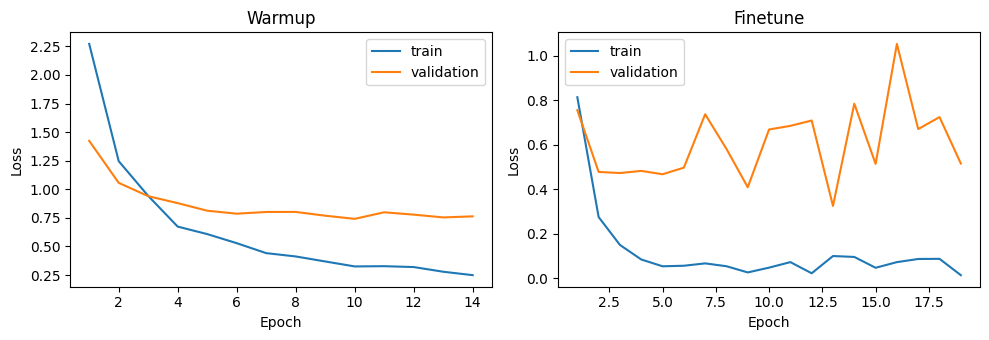

In [3]:
selection = json.loads((RUN_DIR / 'selection.json').read_text(encoding='utf-8'))
print('Selected stage:', selection['selected_stage'])
display(pd.DataFrame(selection['validation']).T)
predictions = pd.read_csv(RUN_DIR / 'validation_predictions.csv')
display(predictions.groupby(['domain', 'correct']).size().unstack(fill_value=0))
display(predictions.groupby(['domain', 'true_identity'])['correct'].agg(['sum', 'count', 'mean']))
display(predictions.loc[~predictions['correct'], ['domain', 'image', 'true_identity', 'predicted_identity', 'confidence']].head(20))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, stage in zip(axes, ('warmup', 'finetune')):
    history = pd.read_csv(RUN_DIR / f'{stage}_epochs.csv')
    ax.plot(history['epoch'] + 1, history['loss'], label='train')
    ax.plot(history['epoch'] + 1, history['val_loss'], label='validation')
    ax.set(title=stage.capitalize(), xlabel='Epoch', ylabel='Loss')
    ax.legend()
fig.tight_layout()
plt.show()